In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tiktoken
import numpy as np
import pandas as pd

# Dictionaries and Functions

In [ ]:
# %%
DICT_ED_01 = {
    "sent_01": "anger",
    "sent_02": "disgust",
    "sent_03": "fear",
    "sent_04": "joy",
    "sent_05": "sadness",
    "sent_06": "surprise",
}
DICT_ED_02 = {
    "joy": "joy",
    "sadness": "sadness",
    "anger": "anger",
    "fear": "fear",
    "love": "love",
    "surprise": "surprise",
}
DICT_ED_03 = {
    0: "admiration",
    1: "amusement",
    2: "anger",
    3: "annoyance",
    4: "approval",
    5: "caring",
    6: "confusion",
    7: "curiosity",
    8: "desire",
    9: "disappointment",
    10: "disapproval",
    11: "disgust",
    12: "embarrassment",
    13: "excitement",
    14: "fear",
    15: "gratitude",
    16: "grief",
    17: "joy",
    18: "love",
    19: "nervousness",
    20: "optimism",
    21: "pride",
    22: "realization",
    23: "relief",
    24: "remorse",
    25: "sadness",
    26: "surprise",
    27: "neutral",
}
DICT_ED_04 = {0: "hope", 1: "not_hope", 2: "other"}
DICT_ED_05 = {
    "sadness": "sadness",
    "anticipation": "anticipation",
    "fear": "fear",
    "anger": "anger",
    "joy": "joy",
}
DICT_FN_01 = {
    0: "false",
    1: "half_true",
    2: "mostly_true",
    3: "true",
    4: "barely_true",
    5: "pants_on_fire",
}
DICT_FN_02 = {"legit": "true", "fake": "false"}
DICT_FN_03 = {
    "half-true": "half_true",
    "false": "false",
    "mostly true": "mostly_true",
    "mostly false": "mostly_false",
    "true": "true",
    "pants on fire": "pants_on_fire",
    "pants on fire!": "pants_on_fire",
    "full flop": "full_flop",
    "half flip": "half_flip",
    "no flip": "no_flip",
}
DICT_FN_04 = {
    "false": "false",
    "mixture": "false_and_true",
    "true": "true",
    "mostly false": "mostly_false",
    "unproven": "unproven",
    "mostly true": "mostly_true",
    "miscaption": "miscaptioned",
    "outdated": "outdated",
    "misattributed": "misattributed",
    "legend": "legend",
    "scam": "scam",
    "correct attribution": "correct_attribution",
}
DICT_FN_05 = {
    "supports": "support",
    "not enough info": "insufficient_info",
    "refutes": "refutation",
}
DICT_FN_06 = {0: "false", 1: "true"}
DICT_FN_07 = {
    "supports": "support",
    "not enough info": "insufficient_info",
    "refutes": "refutation",
}
DICT_FN_08 = {
    "false": "false",
    "misleading": "misleading",
    "mostly false": "mostly_false",
    "partly false": "partly_false",
    "true": "true",
}
DICT_FN_09 = {
    "accept": "false",
    "reject": "true",
    "no stance": "no_opinion",
    "not relevant": "out_of_scope",
}
DICT_FN_10 = {
    "accept": "false",
    "reject": "true",
    "no stance": "no_opinion",
    "not relevant": "out_of_scope",
}
DICT_HS_01 = {"none": "neutral", "sexism": "sexism"}
DICT_HS_02 = {0: "hate", 1: "offensive", 2: "neither"}
DICT_HS_03 = {"hate": "hate", "nohate": "not_hate"}
DICT_HS_04 = {0: "not_toxic", 1: "toxic"}
DICT_HS_05 = {
    "normal": "neither",
    "spam": "spam",
    "abusive": "offensive",
    "hateful": "hate",
}
DICT_HS_06 = {0: "not_hate", 1: "hate"}
DICT_HS_07 = {"not": "not_hate", "off": "offensive"}
DICT_HS_08 = {0: "not_hate", 1: "hate"}
DICT_HS_09 = {0: "not_hate", 1: "hate"}
DICT_HS_10 = {0: "not_hate", 1: "hate"}
DICT_HS_11 = {0: "neutral", 1: "sexism"}
DICT_HS_12 = {0: "not_hate", 1: "hate"}
DICT_HS_13 = {0: "hate", 1: "neither", 2: "offensive"}
DICT_HS_14 = {0: "not_hate", 1: "toxic"}
DICT_HS_15 = {
    "deg": "derogatory",
    "ndg": "non_derogatory_non_appropriative",
    "hom": "homonym",
    "apr": "appropriative",
    "cmp": "noise",
}
DICT_PC_01 = {0: "negative", 1: "positive"}
DICT_PC_02 = {0: "negative", 4: "positive"}
DICT_PC_03 = {"pos": "positive", "neg": "negative"}
DICT_PC_04 = {0: "negative", 1: "positive"}
DICT_PC_05 = {"neutral": "neutral", "positive": "positive", "negative": "negative"}
DICT_PC_06 = {1: "negative", 2: "positive"}
DICT_PC_07 = {-1: "negative", 0: "neutral", 1: "positive"}
DICT_PC_08 = {0: "negative", 1: "neutral", 2: "positive"}
DICT_PC_09 = {0: "negative", 1: "positive", 2: "neutral", 3: "mixed"}
DICT_SD_01 = {"false": "not_hyperpartisan", "true": "hyperpartisan"}
DICT_SD_02 = {0: "right", 1: "right_center", 2: "least", 3: "left-center", 4: "left"}
DICT_SD_03 = {"none": "neutral", "against": "against", "favor": "favorable"}
DICT_SD_04 = {"none": "neutral", "against": "against", "favor": "favorable"}
DICT_UA_01 = {1: "1", 2: "3", 3: "5", 4: "7", 5: "10"}
DICT_UA_02 = {
    1: "1",
    2: "2",
    3: "3",
    4: "4",
    5: "5",
    6: "6",
    7: "7",
    8: "8",
    9: "9",
    10: "10",
}
DICT_UA_03 = {1: "1", 2: "3", 3: "5", 4: "7", 5: "10"}
DICT_UA_04 = {1: "1", 2: "3", 3: "5", 4: "7", 5: "10"}
DICT_UA_05 = {1: "1", 2: "3", 3: "5", 4: "7", 5: "10"}
DICT_UA_06 = {1: "1", 2: "3", 3: "5", 4: "7", 5: "10"}

DICT_DATASET_DICTIONARY_CORRESPONDENCE = {
    "ed_01": DICT_ED_01,
    "ed_02": DICT_ED_02,
    "ed_03": DICT_ED_03,
    "ed_04": DICT_ED_04,
    "ed_05": DICT_ED_05,
    "fn_01": DICT_FN_01,
    "fn_02": DICT_FN_02,
    "fn_03": DICT_FN_03,
    "fn_04": DICT_FN_04,
    "fn_05": DICT_FN_05,
    "fn_06": DICT_FN_06,
    "fn_07": DICT_FN_07,
    "fn_08": DICT_FN_08,
    "fn_09": DICT_FN_09,
    "fn_10": DICT_FN_10,
    "hs_01": DICT_HS_01,
    "hs_02": DICT_HS_02,
    "hs_03": DICT_HS_03,
    "hs_04": DICT_HS_04,
    "hs_05": DICT_HS_05,
    "hs_06": DICT_HS_06,
    "hs_07": DICT_HS_07,
    "hs_08": DICT_HS_08,
    "hs_09": DICT_HS_09,
    "hs_10": DICT_HS_10,
    "hs_11": DICT_HS_11,
    "hs_12": DICT_HS_12,
    "hs_13": DICT_HS_13,
    "hs_14": DICT_HS_14,
    "hs_15": DICT_HS_15,
    "pc_01": DICT_PC_01,
    "pc_02": DICT_PC_02,
    "pc_03": DICT_PC_03,
    "pc_04": DICT_PC_04,
    "pc_05": DICT_PC_05,
    "pc_06": DICT_PC_06,
    "pc_07": DICT_PC_07,
    "pc_08": DICT_PC_08,
    "pc_09": DICT_PC_09,
    "sd_01": DICT_SD_01,
    "sd_02": DICT_SD_02,
    "sd_03": DICT_SD_03,
    "sd_04": DICT_SD_04,
    "ua_01": DICT_UA_01,
    "ua_02": DICT_UA_02,
    "ua_03": DICT_UA_03,
    "ua_04": DICT_UA_04,
    "ua_05": DICT_UA_05,
    "ua_06": DICT_UA_06,
}

In [ ]:
def get_dict_to_rename_labels(str_task_file: str) -> dict:
    """This function returns a dictionary
    with the corresponding labels for a dataset selected in the input.

    Args:
        str_task_file (str): dataset to be selected

    Returns:
        dict: dictionary with its corresponding labels
    """
    return DICT_DATASET_DICTIONARY_CORRESPONDENCE[str_task_file]


def get_dict_correspondence() -> dict:
    """This functions retrieves the dataset relations
    and creates a dictionary with their correspondence

    Returns:
        dict: dictionary that contains the relation between the datasets
    """
    dict_corresp = {}
    relations_df = pd.read_csv(
        "dataset_relations.csv",
        sep=";",
    )
    unique_first_datasets = list(set(relations_df["first_dataset"].tolist()))

    for unique_dataset in unique_first_datasets:
        filtered_relations_df = relations_df.query(
            f"first_dataset.str.contains('{unique_dataset}')"
        )
        dict_corresp[unique_dataset] = list(
            set(filtered_relations_df["second_dataset"].tolist())
        )
        dict_corresp[unique_dataset].sort()

    return dict_corresp


def format_chat_prompt(system: str, user: str) -> str:
    # Format prompt to mimic chat behavior
    return f"<|system|>\n{system}\n<|user|>\n{user}\n<|assistant|>\n"

In [ ]:
# %%

# ed fn hs pc sd ua
# system input
system_input = {
    "ed": "You are responsible for labeling the emotions of texts.",
    "fn": "You are responsible for detecting fake news.",
    "hs": "You are responsible for detecting hate speech.",
    "pc": "You are responsible for classifying the polarity of texts.",
    "sd": "You are responsible for detecting the stance of texts.",
    "ua": "You are responsible for analyzing the utility of texts.",
}

# Cambridge dictionary
emotion_detection_labels = {
    "admiration": "the feeling of admiring someone or something",  # https://dictionary.cambridge.org/dictionary/english/admiration
    "amusement": "the feeling of being entertained or made to laugh",  # https://dictionary.cambridge.org/dictionary/english/amusement
    "anger": "a strong feeling that makes you want to hurt someone or be unpleasant because of something unfair or unkind that has happened",  # https://dictionary.cambridge.org/dictionary/english/amusement
    "annoyance": "the feeling or state of being annoyed",  # https://dictionary.cambridge.org/dictionary/english/annoyance
    "anticipation": "a feeling of excitement about something that is going to happen in the near future",  # https://dictionary.cambridge.org/dictionary/english/anticipation
    "approval": "the feeling of having a positive opinion of someone or something",  # https://dictionary.cambridge.org/dictionary/english/approval
    "caring": "a caring person is kind and gives emotional support to others",  # https://dictionary.cambridge.org/dictionary/english/caring
    "confusion": "a lack of understanding, or a state of disorder",  # https://dictionary.cambridge.org/dictionary/english/confusion
    "curiosity": "an eager wish to know or learn about something",  # https://dictionary.cambridge.org/dictionary/english/curiosity
    "desire": "to want something, especially strongly",  # https://dictionary.cambridge.org/dictionary/english/desire
    "disappointment": "something or someone that is not what you were hoping it would be",  # https://dictionary.cambridge.org/dictionary/english/disappointment
    "disapproval": "the feeling of having a negative opinion of someone or something",  # https://dictionary.cambridge.org/dictionary/english/disapproval
    "disgust": "a strong feeling of disapproval or dislike, or a feeling of becoming ill caused by something unpleasant",  # https://dictionary.cambridge.org/dictionary/english/disgust
    "embarrassment": "the feeling of being embarrassed, or something that makes you feel embarrassed",  # https://dictionary.cambridge.org/dictionary/english/embarrassment
    "excitement": "a feeling of being excited, or an exciting event",  # https://dictionary.cambridge.org/dictionary/english/excitement
    "fear": "an unpleasant emotion or thought that you have when you are frightened or worried by something dangerous, painful, or bad that is happening or might happen",  # https://dictionary.cambridge.org/dictionary/english/fear
    "gratitude": "the feeling or quality of being grateful",  # https://dictionary.cambridge.org/dictionary/english/gratitude
    "grief": "very great sadness, especially at the death of someone",  # https://dictionary.cambridge.org/dictionary/english/grief
    "joy": "great happiness",  # https://dictionary.cambridge.org/dictionary/english/joy
    "love": "the feeling of liking another adult very much and being romantically and sexually attracted to them, or strong feelings of liking a friend or person in your family",  # https://dictionary.cambridge.org/dictionary/english/love
    "nervousness": "a feeling of worry and anxiety",  # https://dictionary.cambridge.org/dictionary/english/nervousness
    "optimism": "the quality of being full of hope and emphasizing the good parts of a situation, or a belief that something good will happen",  # https://dictionary.cambridge.org/dictionary/english/optimism
    "pride": "a feeling of pleasure and satisfaction that you get because you or people connected with you have done or got something good",  # https://dictionary.cambridge.org/dictionary/english/pride
    "realization": "the fact or moment of starting to understand a situation",  # https://dictionary.cambridge.org/dictionary/english/realization
    "relief": "a feeling of happiness that something unpleasant has not happened or has ended",  # https://dictionary.cambridge.org/dictionary/english/relief
    "remorse": "a feeling of sadness and being sorry for something you have done",  # https://dictionary.cambridge.org/dictionary/english/remorse
    "sadness": "the feeling of being unhappy, especially because something bad has happened",  # https://dictionary.cambridge.org/dictionary/english/sadness
    "surprise": "an unexpected event",  # https://dictionary.cambridge.org/dictionary/english/surprise
    "neutral": "not saying or doing anything that would encourage or help any of the groups involved in an argument or war",  # https://dictionary.cambridge.org/dictionary/english/neutral
    "hope": "to want something to happen or to be true, and usually have a good reason to think that it might",  # https://dictionary.cambridge.org/dictionary/english/hope
    "not_hope": "hopeless",  # https://dictionary.cambridge.org/dictionary/english/hopeless
    "other": "it is not about hope or a hopeless speech.",
}


fake_news_detection_labels = {  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "barely_true": "only just accurate and there's nothing significant missing",  # https://dictionary.cambridge.org/dictionary/english/barely https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "correct_attribution": "accurately saying or thinking that something is the result or work of a particular person or thing",  # https://dictionary.cambridge.org/dictionary/english/attribution
    "false": "not real, but made to look or seem real",  # https://dictionary.cambridge.org/dictionary/english/false
    "false_and_true": "accurate in some parts, but not real in others",  # https://dictionary.cambridge.org/dictionary/english/false https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "full_flop": "a complete change in position",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "half_flip": "a partial change in position",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "half_true": "partially accurate but leaves out important details or takes things out of context",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "insufficient_info": "not possible to support or refute a text segment",
    "legend": "a very old story or set of stories from ancient times, or the stories, not always true, that people tell about a famous event or person",  # https://dictionary.cambridge.org/dictionary/english/legend
    "misattributed": "to wrongly say or think that something was created, said, or written by a particular person",  # https://dictionary.cambridge.org/dictionary/english/misattribute
    "miscaptioned": "to provide the wrong piece of text under a picture instead of the text that correctly describes or explains the picture",  # adapted from https://dictionary.cambridge.org/dictionary/english/miscaption
    "misleading": "causing someone to believe something that is not true",  # https://dictionary.cambridge.org/dictionary/english/misleading
    "mostly_false": "an element of truth but ignores critical facts that would give a different impression",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "mostly_true": "accurate but needs clarification or additional information",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "no_flip": "not a significant change in position",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "no_opinion": "not saying or doing anything that would encourage or help true or false claims",  # adapted from neutral definition https://dictionary.cambridge.org/dictionary/english/neutral
    "out_of_scope": "unrelated or barely related to true or false claims",
    "outdated": "no longer useful or accurate",  # adapted from https://dictionary.cambridge.org/dictionary/english/outdated
    "pants_on_fire": "not accurate and makes a ridiculous claim",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "partly_false": "part of it is not real, but made to look or seem real",  # https://dictionary.cambridge.org/dictionary/english/false
    "refutation": "the act of saying or proving that a person, statement, opinion, etc. is wrong or false",  # https://dictionary.cambridge.org/dictionary/english/refutation
    "scam": "a dishonest plan for making money or getting an advantage, especially one that involves tricking people",  # https://dictionary.cambridge.org/dictionary/english/scam
    "support": "to help to show something to be true",  # https://dictionary.cambridge.org/dictionary/english/support
    "true": "accurate and there's nothing significant missing",  # https://www.politifact.com/article/2018/feb/12/principles-truth-o-meter-politifacts-methodology-i/
    "unproven": "not having been shown to be true",  # https://dictionary.cambridge.org/dictionary/english/unproven
}


hate_speech_detection_labels = {
    "appropriative": "taking something for your own use, usually without permission",  # https://dictionary.cambridge.org/dictionary/english/appropriation
    "derogatory": "showing strong disapproval and not showing respect",  # https://dictionary.cambridge.org/dictionary/english/derogatory
    "hate": "an extremely strong dislike",  # https://dictionary.cambridge.org/dictionary/english/hate
    "homonym": "a word that is spelled the same as another word but that does not have the same meaning",  # https://dictionary.cambridge.org/dictionary/english/homonym
    "neither": "not an extremely strong dislike and is not causing offence",  # https://dictionary.cambridge.org/dictionary/english/hate https://dictionary.cambridge.org/dictionary/english/offensive
    "neutral": "not saying or doing anything that would encourage or help any of the groups involved in an argument or war",  # https://dictionary.cambridge.org/dictionary/english/neutral
    "non_derogatory_non_appropriative": "not taking something for your own use, usually without permission and is not showing strong disapproval and not showing respect",  # https://dictionary.cambridge.org/dictionary/english/appropriation https://dictionary.cambridge.org/dictionary/english/derogatory
    "not_hate": "not an extremely strong dislike",  # https://dictionary.cambridge.org/dictionary/english/hate
    "not_toxic": "not unpleasant or unacceptable",  # https://dictionary.cambridge.org/dictionary/english/toxic
    "noise": "not related to hate or offensive speech",
    "offensive": "causing offence",  # https://dictionary.cambridge.org/dictionary/english/offensive
    "sexism": "the belief that the members of one sex are less intelligent, able, skilful, etc. than the members of the other sex, especially that women are less able than men",  # https://dictionary.cambridge.org/dictionary/english/sexism
    "spam": "unwanted email, usually advertisements",  # https://dictionary.cambridge.org/dictionary/english/spam
    "toxic": "very unpleasant or unacceptable",  # https://dictionary.cambridge.org/dictionary/english/toxic
}


stance_detection_labels = {
    "not_hyperpartisan": "not an extremely partisan and extremely biased in favor of a political party",  # https://en.wiktionary.org/wiki/hyperpartisan
    "hyperpartisan": "extremely partisan and extremely biased in favor of a political party",  # https://en.wiktionary.org/wiki/hyperpartisan
    "right": "the political parties or people that have traditional opinions, and that believe in low taxes, property, and industry being privately owned, and less help for the poor",  # https://dictionary.cambridge.org/dictionary/english/right
    "right_center": "a political belief that contains some conservative ideas but is not extreme",  # https://dictionary.cambridge.org/dictionary/english/right-of-centre
    "least": "not saying or doing anything that would encourage or help any of the political groups",  # adapted from neutral definition https://dictionary.cambridge.org/dictionary/english/neutral
    "left-center": "a political belief that contains some socialist ideas but is not extreme",  # https://dictionary.cambridge.org/dictionary/english/left-of-centre
    "left": "the political groups that believe wealth and power should be shared between all parts of society",  # https://dictionary.cambridge.org/dictionary/english/left
    "neutral": "not saying or doing anything that would encourage or help any of the groups",  # adapted from neutral definition https://dictionary.cambridge.org/dictionary/english/neutral
    "against": "opposed to someone or something",  # adapted from https://dictionary.cambridge.org/dictionary/english/against
    "favorable": "when support or approve of someone or something",  # adapted from https://dictionary.cambridge.org/dictionary/english/favourable
}

utility_analysis_labels = {
    "1": "extremely low",
    "2": "very low",
    "3": "low",
    "4": "slightly below average",
    "5": "average",
    "6": "slightly above average",
    "7": "good",
    "8": "very good",
    "9": "excellent",
    "10": "optimal",
}

polarity_classification_labels = {
    "negative": "bad or harmful",  # https://dictionary.cambridge.org/dictionary/english/negative
    "positive": "full of hope and confidence",  # https://dictionary.cambridge.org/dictionary/english/positive
    "neutral": "not saying or doing anything that would encourage or help any of the groups",  # adapted from neutral definition https://dictionary.cambridge.org/dictionary/english/neutral
    "mixed": "positive and negative opinions",
}

selected_dictionary_with_labels = {
    "ed": emotion_detection_labels,
    "fn": fake_news_detection_labels,
    "hs": hate_speech_detection_labels,
    "pc": polarity_classification_labels,
    "sd": stance_detection_labels,
    "ua": utility_analysis_labels,
}

In [ ]:
df_files = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/zero_and_few_shot_files.csv",
    sep=";",
    encoding='utf-8'
)

NUMBER_OF_EXAMPLES = 0
TOTAL_NUMBER_TOKENS = 0
MAX_CONTEXT_WINDOW_LENGTH = 100_000
LENGTH_LIMIT = 39_000
encoding = tiktoken.get_encoding("r50k_base") # simplified estimation with tiktoken

df_result = pd.DataFrame()

datasets = df_files["name_dataset"].unique().tolist()
for idx, dataset in enumerate(datasets):
    if "sd_02" in dataset:
        continue
    print(f"{idx}/{len(datasets)}: Running {dataset}")

    filtered_files_df = df_files[df_files["name_dataset"] == dataset]
    collected_prompt_data_list = []
    collect_results_list = []

    df = pd.read_csv(
        f"/content/drive/MyDrive/Colab Notebooks/{filtered_files_df['name_file_llm'].iloc[0]}",
        sep=";",
    )

    df_predict = pd.read_csv(
        f"/content/drive/MyDrive/Colab Notebooks/{filtered_files_df['name_file_predict'].iloc[0]}",
        sep=";",
    )
    df_predict = df_predict.dropna()

    if pd.api.types.is_bool_dtype(df_predict["label"]):
        df_predict["label"] = df_predict["label"].apply(lambda x: str(x).lower())
    try:
        df_predict["label"] = df_predict["label"].apply(lambda x: x.lower())
    except Exception:
        pass
    dict_replacement = get_dict_to_rename_labels(filtered_files_df["name_dataset"].iloc[0])
    df_predict["label"] = df_predict["label"].replace(dict_replacement)

    collected_labels = df["label"].unique().tolist()
    collected_labels = [str(item).lower() for item in collected_labels]
    try:
        collected_labels = [int(item) for item in collected_labels]
        collected_labels.sort()
        collected_labels = [str(item) for item in collected_labels]
    except Exception:
        collected_labels.sort()

    collected_labels_str = ", ".join(collected_labels)
    description_task = f"It is necessary to classify a text segment using one of the {len(collected_labels)} labels: {collected_labels_str}.\nThe following lines mention the labels and define them.\n"

    task = filtered_files_df["name_dataset"].iloc[0].split("_")[0]
    context_sentence = system_input[task]
    task_dictionary = selected_dictionary_with_labels[task]

    base_prompt = ""
    base_prompt = base_prompt + f"{context_sentence}\n{description_task}"

    TOTAL_TOKENS_CURRENT_PROMPT = len(encoding.encode(base_prompt))

    label_definition_example_dict = {}
    label_definition_example_dict = {
        item: [f"\nLabel: {item}", f"Definition: {task_dictionary[item]} \nExamples:"]
        for item in collected_labels
    }

    for element in label_definition_example_dict.values():
        TOTAL_TOKENS_CURRENT_PROMPT += len(encoding.encode("\n".join(element)))

    if task == "ua":
        df["label"] = df["label"].astype(str)
    for count_instance in range(NUMBER_OF_EXAMPLES):
        if (
            TOTAL_TOKENS_CURRENT_PROMPT < MAX_CONTEXT_WINDOW_LENGTH
        ):  # defined max context window length
            for label in collected_labels:

                df_filtered = df[df["label"] == label]
                examples_list = list(df_filtered["text"])
                try:
                    instance_example = examples_list[count_instance]
                    number_tokens_instance = len(encoding.encode(instance_example))
                except IndexError:
                    continue
                if (
                    TOTAL_TOKENS_CURRENT_PROMPT + number_tokens_instance
                ) > MAX_CONTEXT_WINDOW_LENGTH:
                    break
                label_definition_example_dict[label].append(instance_example)
                TOTAL_TOKENS_CURRENT_PROMPT += number_tokens_instance

        else:
            break

    for selected_label in collected_labels:
        base_prompt = (
            base_prompt
            + "\n"
            + "\n".join(label_definition_example_dict[selected_label])
            + "\n"
        )

    base_prompt = base_prompt + "\nLabel the following text: '"

    instances_to_predict_list = list(df_predict["text"])
    number_instance_prediction = len(instances_to_predict_list)

    for counter_pred in range(number_instance_prediction):
        instance = instances_to_predict_list[counter_pred]
        final_prompt = base_prompt + f"{instance}'\nReturn only the selected label."

        df_result = pd.concat(
            [
                pd.DataFrame(
                    dict(
                        dataset=dataset,
                        prompt_len=len(final_prompt),
                        number_of_examples=NUMBER_OF_EXAMPLES,
                        num_labels=len(collected_labels)
                    ),
                    index=[0]
                ),
                df_result
            ]
        )

df_result

0/49: Running ed_01
1/49: Running ed_02
2/49: Running ed_03
3/49: Running ed_04
4/49: Running ed_05
5/49: Running fn_01
6/49: Running fn_02
7/49: Running fn_03
8/49: Running fn_04
9/49: Running fn_05
10/49: Running fn_06
11/49: Running fn_07
12/49: Running fn_08
13/49: Running fn_09
14/49: Running fn_10
15/49: Running hs_01
16/49: Running hs_02
17/49: Running hs_03
18/49: Running hs_04
19/49: Running hs_05
20/49: Running hs_06
21/49: Running hs_07
22/49: Running hs_08
23/49: Running hs_09
24/49: Running hs_10
25/49: Running hs_11
26/49: Running hs_12
27/49: Running hs_13
28/49: Running hs_14
29/49: Running hs_15
30/49: Running pc_01
31/49: Running pc_02
32/49: Running pc_03
33/49: Running pc_04
34/49: Running pc_05
35/49: Running pc_06
36/49: Running pc_07
37/49: Running pc_08
38/49: Running pc_09
39/49: Running sd_01
41/49: Running sd_03
42/49: Running sd_04
43/49: Running ua_01
44/49: Running ua_02
45/49: Running ua_03
46/49: Running ua_04
47/49: Running ua_05
48/49: Running ua_06


,dataset,prompt_len,number_of_examples,num_labels
0,ua_06,1045,0,5
0,ua_06,874,0,5
0,ua_06,1128,0,5
0,ua_06,650,0,5
0,ua_06,1032,0,5
...,...,...,...,...
0,ed_01,1051,0,6
0,ed_01,1057,0,6
0,ed_01,1056,0,6
0,ed_01,1043,0,6


In [ ]:
import pandas as pd

zero_shot = pd.read_csv(f"/content/drive/MyDrive/Colab Notebooks/prompt_size_per_dataset_0-shot.csv", sep=";")
zero_shot

,dataset,prompt_len,number_of_examples,num_labels
0,ua_06,1045,0,5
1,ua_06,874,0,5
2,ua_06,1128,0,5
3,ua_06,650,0,5
4,ua_06,1032,0,5
...,...,...,...,...
814413,ed_01,1051,0,6
814414,ed_01,1057,0,6
814415,ed_01,1056,0,6
814416,ed_01,1043,0,6


In [ ]:
prompt_len_per_dataset_median = (
    zero_shot.groupby(["dataset"], as_index=False)
    .agg(
        {
          "prompt_len": "median",
          "num_labels": "count"
        }
    )
    .rename(
        columns={
            "prompt_len": "prompt_len_median",
            "num_labels": "number_of_instances",
        }
    )
)
prompt_len_per_dataset_mean = (
    zero_shot.groupby(["dataset"], as_index=False)
    .agg(
        {
          "prompt_len": "mean",
        }
    )
    .rename(
        columns={
            "prompt_len": "prompt_len_mean",
        }
    )
)
prompt_len_per_dataset = prompt_len_per_dataset_mean.merge(prompt_len_per_dataset_median, on="dataset")
final = (
      zero_shot.merge(prompt_len_per_dataset, on="dataset")
      .drop_duplicates(["dataset"])
      [["dataset", "number_of_examples", "num_labels", "number_of_instances", "prompt_len_median", "prompt_len_mean"]]
      .sort_values("prompt_len_median", ignore_index=True, ascending=False)
)
final

,dataset,number_of_examples,num_labels,number_of_instances,prompt_len_median,prompt_len_mean
0,ed_03,0,28,10832,3730.0,3733.361521
1,sd_01,0,2,192,2936.5,3620.760417
2,pc_08,0,3,1399,2144.0,2520.606862
3,fn_06,0,2,237,1995.0,2259.540084
4,fn_04,0,12,1526,1877.0,1881.202490
5,pc_03,0,2,24800,1327.0,1647.238347
6,fn_03,0,9,3493,1257.0,1264.177784
7,ed_02,0,6,116942,1159.0,1170.463076
8,fn_02,0,2,144,1089.0,1127.597222
9,ed_01,0,6,241,1059.0,1058.991701


In [ ]:
NUMBER_OF_EXAMPLES = 0
mistral = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/mistral.csv",
    sep=";"
)
llama = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/llama.csv",
    sep=";"
)
mistral = mistral.loc[mistral["number_of_examples"] == NUMBER_OF_EXAMPLES, ["predicted_dataset", "hold_out_f1_score"]]
mistral["system"] = "mistral"

llama = llama.loc[llama["number_of_examples"] == NUMBER_OF_EXAMPLES, ["predicted_dataset", "hold_out_f1_score"]]
llama["system"] = "llama"

In [ ]:
stats = (
    final
    .merge(
        llama.rename(columns={"hold_out_f1_score": "hold_out_f1_score_llama"}),
        left_on="dataset",
        right_on="predicted_dataset",
    )
    .merge(
        mistral.rename(columns={"hold_out_f1_score": "hold_out_f1_score_mistral"}),
        left_on="dataset",
        right_on="predicted_dataset",
    )
)
stats

,dataset,number_of_examples,num_labels,number_of_instances,prompt_len_median,prompt_len_mean,predicted_dataset_x,hold_out_f1_score_llama,system_x,predicted_dataset_y,hold_out_f1_score_mistral,system_y
0,ed_03,0,28,10832,3730.0,3733.361521,ed_03,0.199409,llama,ed_03,0.280096,mistral
1,sd_01,0,2,192,2936.5,3620.760417,sd_01,0.770833,llama,sd_01,0.541667,mistral
2,pc_08,0,3,1399,2144.0,2520.606862,pc_08,0.349535,llama,pc_08,0.363831,mistral
3,fn_06,0,2,237,1995.0,2259.540084,fn_06,0.540084,llama,fn_06,0.472574,mistral
4,fn_04,0,12,1526,1877.0,1881.202490,fn_04,0.113368,llama,fn_04,0.250328,mistral
5,pc_03,0,2,24800,1327.0,1647.238347,pc_03,0.916774,llama,pc_03,0.871895,mistral
6,fn_03,0,9,3493,1257.0,1264.177784,fn_03,0.181792,llama,fn_03,0.219582,mistral
7,ed_02,0,6,116942,1159.0,1170.463076,ed_02,0.566905,llama,ed_02,0.602581,mistral
8,fn_02,0,2,144,1089.0,1127.597222,fn_02,0.687500,llama,fn_02,0.569444,mistral
9,ed_01,0,6,241,1059.0,1058.991701,ed_01,0.381743,llama,ed_01,0.481328,mistral


<Axes: title={'center': 'Llama Prompt Length: -0.18'}, xlabel='prompt_len_median', ylabel='hold_out_f1_score_llama'>

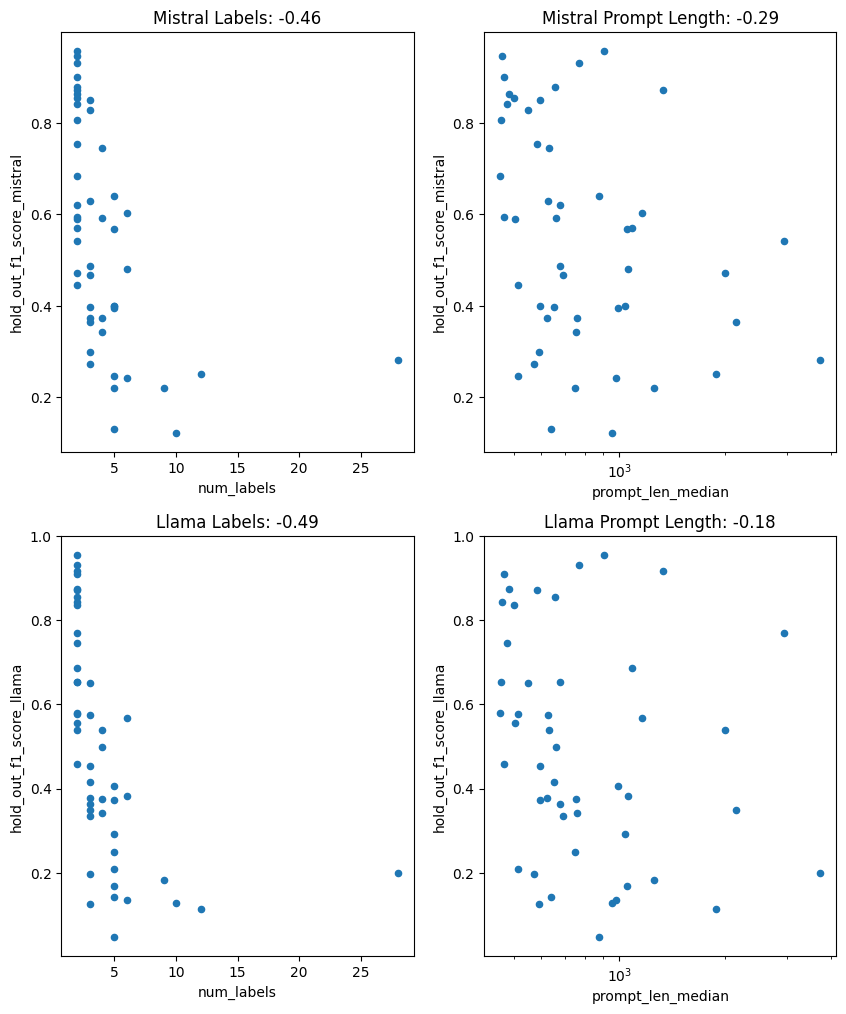

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 12))

corr_mistral = round(stats["hold_out_f1_score_mistral"].corr(stats["prompt_len_median"]), 2)
corr_llama = round(stats["hold_out_f1_score_llama"].corr(stats["prompt_len_median"]), 2 )

corr_num_labels_mistral = round(stats["hold_out_f1_score_mistral"].corr(stats["num_labels"]), 2)
corr_num_labels_llama = round(stats["hold_out_f1_score_llama"].corr(stats["num_labels"]), 2 )

stats.plot.scatter(x="num_labels", y="hold_out_f1_score_mistral", ax=axes[0, 0], title=f"Mistral Labels: {corr_num_labels_mistral}")
stats.plot.scatter(x="prompt_len_median", y="hold_out_f1_score_mistral", ax=axes[0, 1], title=f"Mistral Prompt Length: {corr_mistral}", logx=True)

stats.plot.scatter(x="num_labels", y="hold_out_f1_score_llama", ax=axes[1, 0], title=f"Llama Labels: {corr_num_labels_llama}")
stats.plot.scatter(x="prompt_len_median", y="hold_out_f1_score_llama", ax=axes[1, 1], title=f"Llama Prompt Length: {corr_llama}", logx=True)
# final

<Axes: title={'center': 'Llama Prompt Length: -0.12'}, xlabel='prompt_len_mean', ylabel='hold_out_f1_score_llama'>

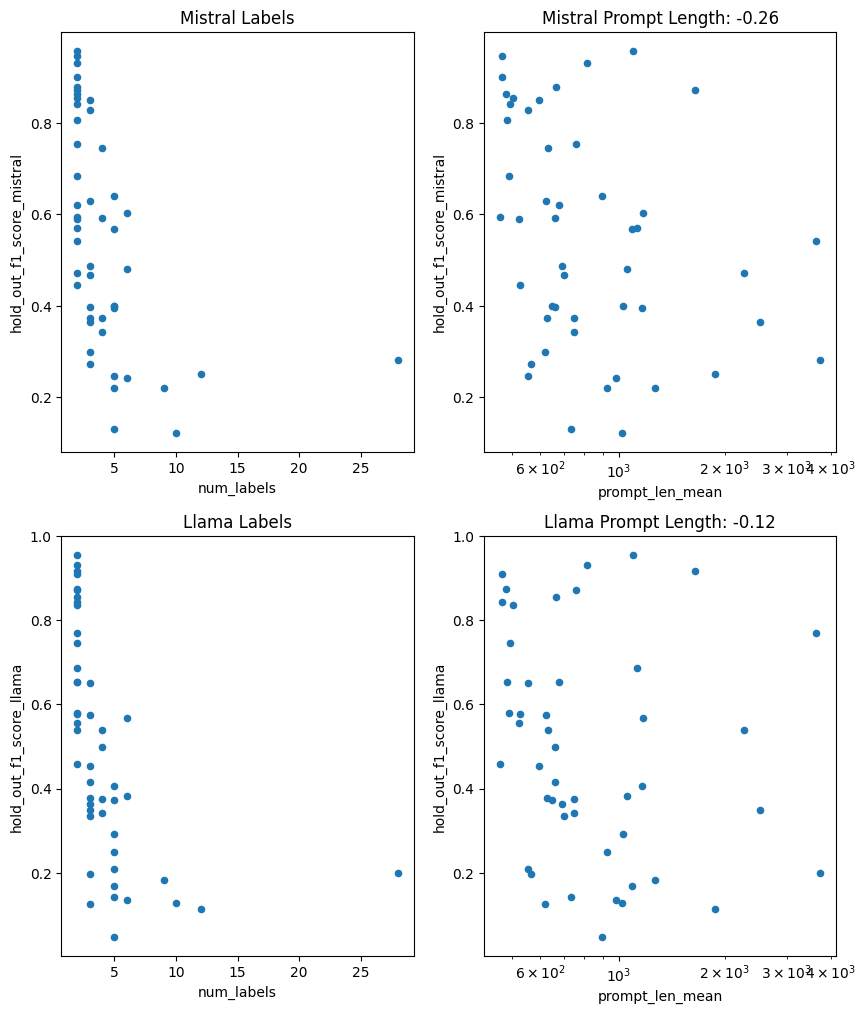

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 12))

corr_mistral = round(stats["hold_out_f1_score_mistral"].corr(stats["prompt_len_mean"]), 2)
corr_llama = round(stats["hold_out_f1_score_llama"].corr(stats["prompt_len_mean"]), 2 )

stats.plot.scatter(x="num_labels", y="hold_out_f1_score_mistral", ax=axes[0, 0], title="Mistral Labels")
stats.plot.scatter(x="prompt_len_mean", y="hold_out_f1_score_mistral", ax=axes[0, 1], title=f"Mistral Prompt Length: {corr_mistral}", logx=True)

stats.plot.scatter(x="num_labels", y="hold_out_f1_score_llama", ax=axes[1, 0], title="Llama Labels")
stats.plot.scatter(x="prompt_len_mean", y="hold_out_f1_score_llama", ax=axes[1, 1], title=f"Llama Prompt Length: {corr_llama}", logx=True)
# final